In [1]:
import numpy as np
import pandas as pd
import statsmodels.api as sm
from scipy.stats import f
from sklearn.model_selection import train_test_split, KFold
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import r2_score, mean_squared_error


In [2]:
# 1. Загрузка данных и разбиение выборок

df = pd.read_csv("regression_data.csv")

target = "Стоимость_квартиры_тыс_руб"
X = df.drop(columns=[target])
y = df[target]

# 60% — train, 20% — validation, 20% — test
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42
)

print("Train:", X_train.shape)
print("Validation:", X_val.shape)
print("Test:", X_test.shape)
print("Пропуски:", df.isna().sum().sum())

Train: (480, 12)
Validation: (160, 12)
Test: (160, 12)
Пропуски: 0


In [3]:
# 2. Статистическая проверка полной модели

# ID исключаем: это идентификатор, а не характеристика квартиры
X_stat = X_train.drop(columns=["ID_объекта"]).copy()

# Кодируем категориальный признак
X_stat = pd.get_dummies(
    X_stat,
    columns=["День_недели_публикации"],
    drop_first=True,
    dtype=float
).astype(float)

# Добавляем свободный член b0
X_stat = sm.add_constant(X_stat)
model = sm.OLS(y_train, X_stat).fit()

alpha = 0.05
n = len(y_train)
k = int(model.df_model)
R2 = model.rsquared

# Проверка значимости модели по критерию Фишера
F_value = (R2 / k) / ((1 - R2) / (n - k - 1))
F_critical = f.ppf(1 - alpha, k, n - k - 1)

print("R² =", round(R2, 6))
print("F =", round(F_value, 3))
print("F критическое =", round(F_critical, 3))
print("Модель значима:", F_value > F_critical)

# Проверка коэффициентов по критерию Стьюдента
results = pd.DataFrame({
    "Коэффициент": model.params,
    "t-статистика": model.tvalues,
    "p-value": model.pvalues,
    "Значимость": model.pvalues < alpha
})

print("\nПроверка коэффициентов:")
print(results.round(4).to_string())

# Корреляции исходных числовых признаков
X_corr = X_train.drop(
    columns=["ID_объекта", "День_недели_публикации"]
).select_dtypes(include="number")

corr_matrix = X_corr.corr(method="pearson")

print("\nМатрица парных корреляций:")
print(corr_matrix.round(3).to_string())

R² = 0.993861
F = 4684.913
F критическое = 1.665
Модель значима: True

Проверка коэффициентов:
                           Коэффициент  t-статистика  p-value  Значимость
const                      -88738.8235      -32.2987   0.0000        True
Общая_площадь_м2              179.6399       51.2352   0.0000        True
Жилая_площадь_м2               -3.6140       -0.7169   0.4738       False
Количество_комнат             -34.6302       -0.8501   0.3957       False
Этаж                           24.4311        8.3561   0.0000        True
Год_постройки                  45.7334       33.3962   0.0000        True
Расстояние_до_метро_мин       -70.2552       -1.9974   0.0464        True
Расстояние_до_метро_м          -0.3432       -0.7822   0.4345       False
Номер_подъезда                 16.8607        2.0863   0.0375        True
Код_домофона                   -0.0476       -0.5705   0.5686       False
Случайный_показатель_шум       -1.0400       -0.7385   0.4606       False
День_недели_публи

In [5]:
# 3. Отбор признаков и проверка сокращённой модели

# Оставляем значимые признаки, избегая сильной мультиколлинеарности
selected_features = [
    "Общая_площадь_м2",
    "Этаж",
    "Год_постройки",
    "Расстояние_до_метро_мин",
    "Номер_подъезда"
]

# Обновлённые выборки
X_train_new = X_train[selected_features].copy()
X_val_new = X_val[selected_features].copy()
X_test_new = X_test[selected_features].copy()

y_train_new = y_train.copy()
y_val_new = y_val.copy()
y_test_new = y_test.copy()

# Повторная статистическая проверка сокращённой модели
X_ols = sm.add_constant(X_train_new)
model_new = sm.OLS(y_train_new, X_ols).fit()

n = len(y_train_new)
k = len(selected_features)
alpha = 0.05

R2_new = model_new.rsquared
F_new = (R2_new / k) / (
    (1 - R2_new) / (n - k - 1)
)
F_critical_new = f.ppf(
    1 - alpha, k, n - k - 1
)

print("R² =", round(R2_new, 6))
print("F =", round(F_new, 3))
print("F критическое =", round(F_critical_new, 3))
print("Модель значима:", F_new > F_critical_new)

print("\nЗначимость коэффициентов:")
print(pd.DataFrame({
    "Коэффициент": model_new.params,
    "t-статистика": model_new.tvalues,
    "p-value": model_new.pvalues,
    "Значим": model_new.pvalues < alpha
}).round(4))

print("\nКорреляции обновлённых признаков:")
print(X_train_new.corr().round(3))

print("\nРазмеры:")
print("Train:", X_train_new.shape)
print("Val:", X_val_new.shape)
print("Test:", X_test_new.shape)

R² = 0.993724
F = 15009.854
F критическое = 2.233
Модель значима: True

Значимость коэффициентов:
                         Коэффициент  t-статистика  p-value  Значим
const                    -88353.7005      -32.5927    0.000    True
Общая_площадь_м2            176.1928      269.0077    0.000    True
Этаж                         24.2731        8.3302    0.000    True
Год_постройки                45.5078       33.6425    0.000    True
Расстояние_до_метро_мин     -97.6683      -43.8792    0.000    True
Номер_подъезда               15.6540        1.9734    0.049    True

Корреляции обновлённых признаков:
                         Общая_площадь_м2   Этаж  Год_постройки  \
Общая_площадь_м2                    1.000 -0.086         -0.030   
Этаж                               -0.086  1.000         -0.095   
Год_постройки                      -0.030 -0.095          1.000   
Расстояние_до_метро_мин             0.013 -0.022         -0.057   
Номер_подъезда                     -0.004  0.070        

In [6]:
# 4. Сравнение методов и шагов обучения

# Подготовка данных
Xtr_raw = X_train_new.to_numpy(dtype=float)
Xv_raw = X_val_new.to_numpy(dtype=float)
ytr_raw = y_train_new.to_numpy(dtype=float)
yv_raw = y_val_new.to_numpy(dtype=float)

def scale_data(Xtr, ytr, Xother):
    sx = StandardScaler().fit(Xtr)
    sy = StandardScaler().fit(ytr.reshape(-1, 1))
    return (
        sx.transform(Xtr),
        sy.transform(ytr.reshape(-1, 1)).ravel(),
        sx.transform(Xother),
        sx, sy
    )

# Реализации методов градиентного спуска
def fit_gd(X, y, method, eta0, schedule, lam=0.01,
           epochs=200, seed=42):
    n, p = X.shape
    rng = np.random.default_rng(seed)
    w = np.zeros(p)
    b = 0.0

    # Параметры Momentum и Adam
    velocity_w = np.zeros(p)
    velocity_b = 0.0
    mw, vw = np.zeros(p), np.zeros(p)
    mb, vb = 0.0, 0.0
    beta1, beta2 = 0.9, 0.999
    eps = 1e-8

    # SAG: храним градиент каждого объекта
    grad_w = np.zeros((n, p))
    grad_b = np.zeros(n)
    avg_w = np.zeros(p)
    avg_b = 0.0

    def step_rate(t):
        if schedule == "constant":
            return eta0
        return eta0 / (1 + lam * t)

    t = 0
    for epoch in range(epochs):
        if method in ("SGD", "SAG"):
            order = rng.permutation(n)
        else:
            order = np.arange(n)

        for i in order:
            t += 1
            eta = step_rate(t)

            if method in ("VGD", "Momentum", "Adam"):
                error = X @ w + b - y
                gw = 2 * (X.T @ error) / n
                gb = 2 * error.mean()

                if method == "VGD":
                    w -= eta * gw
                    b -= eta * gb

                elif method == "Momentum":
                    velocity_w = 0.9 * velocity_w + gw
                    velocity_b = 0.9 * velocity_b + gb
                    w -= eta * velocity_w
                    b -= eta * velocity_b

                else:  # Adam
                    mw = beta1 * mw + (1 - beta1) * gw
                    vw = beta2 * vw + (1 - beta2) * gw**2
                    mb = beta1 * mb + (1 - beta1) * gb
                    vb = beta2 * vb + (1 - beta2) * gb**2

                    mw_hat = mw / (1 - beta1**t)
                    vw_hat = vw / (1 - beta2**t)
                    mb_hat = mb / (1 - beta1**t)
                    vb_hat = vb / (1 - beta2**t)

                    w -= eta * mw_hat / (np.sqrt(vw_hat) + eps)
                    b -= eta * mb_hat / (np.sqrt(vb_hat) + eps)

                # Полные методы делают одно обновление за эпоху
                break

            xi = X[i]
            error_i = xi @ w + b - y[i]
            gi_w = 2 * error_i * xi
            gi_b = 2 * error_i

            if method == "SGD":
                w -= eta * gi_w
                b -= eta * gi_b

            elif method == "SAG":
                avg_w += (gi_w - grad_w[i]) / n
                avg_b += (gi_b - grad_b[i]) / n
                grad_w[i] = gi_w
                grad_b[i] = gi_b
                w -= eta * avg_w
                b -= eta * avg_b

    return w, b


def predict(X, params):
    w, b = params
    return X @ w + b


# Сетка постоянных и функциональных шагов
methods = ["VGD", "SGD", "SAG", "Momentum", "Adam"]

configs = [
    ("constant", eta, 0.0)
    for eta in [0.001, 0.01, 0.05, 0.1]
] + [
    ("functional", eta, lam)
    for eta in [0.01, 0.05, 0.1]
    for lam in [0.001, 0.01]
]

# Перебор конфигураций и оценка качества
results = []
kf = KFold(n_splits=5, shuffle=True, random_state=42)

for method in methods:
    for schedule, eta, lam in configs:
        # Обучение на train, оценка на val
        Xtr, ytr, Xv, sx, sy = scale_data(
            Xtr_raw, ytr_raw, Xv_raw
        )

        params = fit_gd(
            Xtr, ytr, method, eta, schedule, lam
        )

        pred_val_scaled = predict(Xv, params)
        pred_val = sy.inverse_transform(
            pred_val_scaled.reshape(-1, 1)
        ).ravel()

        r2 = r2_score(yv_raw, pred_val)
        rmse_val = np.sqrt(
            mean_squared_error(yv_raw, pred_val)
        )

        # 5-fold CV только на train
        cv_errors = []
        for tr_idx, cv_idx in kf.split(Xtr_raw):
            X_a, y_a = Xtr_raw[tr_idx], ytr_raw[tr_idx]
            X_b, y_b = Xtr_raw[cv_idx], ytr_raw[cv_idx]

            Xa, ya, Xb, _, sy_cv = scale_data(X_a, y_a, X_b)

            p_cv = fit_gd(
                Xa, ya, method, eta, schedule, lam,
                epochs=200, seed=42
            )

            pred_scaled = predict(Xb, p_cv)
            pred = sy_cv.inverse_transform(
                pred_scaled.reshape(-1, 1)
            ).ravel()

            cv_errors.append(
                np.mean((y_b - pred) ** 2)
            )

        cv_rmse = np.sqrt(np.mean(cv_errors))

        results.append({
            "Метод": method,
            "Тип шага": schedule,
            "eta0": eta,
            "lambda": lam if schedule == "functional" else np.nan,
            "R2_val": r2,
            "RMSE_val": rmse_val,
            "RMSE_CV": cv_rmse
        })

results_df = pd.DataFrame(results)
results_df = results_df.replace([np.inf, -np.inf], np.nan)
results_df = results_df.dropna(subset=["R2_val", "RMSE_CV"])

# Сортировка: сначала минимальная ошибка CV, затем максимальный R²
results_df = results_df.sort_values(
    ["RMSE_CV", "R2_val"],
    ascending=[True, False]
).reset_index(drop=True)

print("Все результаты:")
print(results_df.round(4).to_string(index=False))

print("\nЛучшие 10 конфигураций:")
print(results_df.head(10).round(4).to_string(index=False))

# Сводная сравнительная таблица по методам
summary = results_df.groupby("Метод").agg(
    Лучший_R2_val=("R2_val", "max"),
    Минимальный_RMSE_val=("RMSE_val", "min"),
    Минимальный_RMSE_CV=("RMSE_CV", "min")
).sort_values("Минимальный_RMSE_CV")

print("\nСравнение методов:")
print(summary.round(4))

Все результаты:
   Метод   Тип шага  eta0  lambda        R2_val     RMSE_val      RMSE_CV
     SGD functional 0.050   0.001  9.943000e-01 4.491002e+02 4.661104e+02
Momentum functional 0.050   0.001  9.943000e-01 4.491509e+02 4.661475e+02
Momentum functional 0.100   0.010  9.943000e-01 4.491531e+02 4.661493e+02
     VGD functional 0.050   0.010  9.943000e-01 4.491125e+02 4.661521e+02
    Adam   constant 0.100     NaN  9.943000e-01 4.491282e+02 4.661529e+02
    Adam   constant 0.050     NaN  9.943000e-01 4.491049e+02 4.661536e+02
Momentum   constant 0.100     NaN  9.943000e-01 4.491573e+02 4.661536e+02
    Adam functional 0.050   0.001  9.943000e-01 4.491258e+02 4.661544e+02
Momentum   constant 0.010     NaN  9.943000e-01 4.491151e+02 4.661545e+02
    Adam functional 0.100   0.010  9.943000e-01 4.491315e+02 4.661545e+02
     VGD functional 0.050   0.001  9.943000e-01 4.491287e+02 4.661553e+02
     VGD   constant 0.050     NaN  9.943000e-01 4.491287e+02 4.661553e+02
     SAG functional 0.

## 5. Тестирование лучшей конфигурации

Обучаем выбранный метод на `train` и один раз оцениваем его на независимой выборке `test`. Масштабирование обучается только на `train`.

In [8]:
# Лучшие параметры из эксперимента
best_method = "SGD"
best_eta0 = 0.05
best_lambda = 0.001
best_schedule = "functional"

# Масштабируем данные, используя только train
Xtr, ytr, Xte, sx, sy = scale_data(
    X_train_new.to_numpy(dtype=float),
    y_train_new.to_numpy(dtype=float),
    X_test_new.to_numpy(dtype=float)
)

# Обучаем лучшую модель
best_params = fit_gd(
    Xtr,
    ytr,
    method=best_method,
    eta0=best_eta0,
    schedule=best_schedule,
    lam=best_lambda,
    epochs=200,
    seed=42
)

# Предсказание на test
y_pred_scaled = predict(Xte, best_params)
y_pred_test = sy.inverse_transform(
    y_pred_scaled.reshape(-1, 1)
).ravel()

y_true_test = y_test_new.to_numpy(dtype=float)

# Итоговые метрики
r2_test = r2_score(y_true_test, y_pred_test)
rmse_test = np.sqrt(
    mean_squared_error(y_true_test, y_pred_test)
)
mae_test = np.mean(np.abs(y_true_test - y_pred_test))

print("Лучший метод:", best_method)
print("Тип шага:", best_schedule)
print("eta0:", best_eta0)
print("lambda:", best_lambda)
print("R² на test:", round(r2_test, 6))
print("RMSE на test:", round(rmse_test, 4))
print("MAE на test:", round(mae_test, 4))

Лучший метод: SGD
Тип шага: functional
eta0: 0.05
lambda: 0.001
R² на test: 0.994105
RMSE на test: 468.9653
MAE на test: 375.2621


# 6. Вывод

В работе проверена статистическая значимость регрессионной модели, оценена значимость коэффициентов и исследованы парные корреляции признаков. После исключения незначимых и избыточных характеристик оставлены пять признаков: общая площадь квартиры, этаж, год постройки, время до метро и номер подъезда.

Сравнивались методы VGD, SGD, SAG, Momentum и Adam с постоянными и функциональными шагами. По минимальному RMSE кросс-валидации среди проверенных конфигураций выбран SGD с функциональным шагом

\[
\eta_k=\frac{0{,}05}{1+0{,}001k}.
\]

На валидационной выборке получены \(R^2=0{,}9943\), RMSE = 449,1002 и RMSE кросс-валидации = 466,1104. На тестовой выборке получены \(R^2=0{,}994105\), RMSE = 468,9653 и MAE = 375,2621. Таким образом, выбранная конфигурация показала высокое качество прогнозирования на данном наборе данных.

В эксперименте использовалась 5-блочная кросс-валидация; перебирались указанные в коде значения шагов, а не все возможные значения параметров.

## 7. Анимированные визуализации

Три GIF-графика воспроизводятся один раз и остаются на последнем кадре. Матрица корреляций сначала появляется целиком, затем плавно окрашивается. Копии GIF сохраняются в папку `animations`.

In [14]:
# GIF проигрываются один раз и останавливаются на последнем кадре.
# Если Pillow не установлен: %pip install pillow
from PIL import Image as PILImage, ImageDraw, ImageFont, ImageColor
from IPython.display import Image as NotebookImage, display
from io import BytesIO
from pathlib import Path
from functools import lru_cache

@lru_cache(maxsize=32)
def chart_font(size, bold=False):
    candidates = (["C:/Windows/Fonts/arialbd.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans-Bold.ttf"] if bold else
                  ["C:/Windows/Fonts/arial.ttf", "/usr/share/fonts/truetype/dejavu/DejaVuSans.ttf"])
    for path in candidates:
        if Path(path).exists():
            return ImageFont.truetype(path, size)
    return ImageFont.load_default()

def smooth(t):
    t = float(np.clip(t, 0, 1))
    return t*t*(3-2*t)

def mix_color(start, end, progress):
    a = ImageColor.getrgb(start) if isinstance(start, str) else start
    b = ImageColor.getrgb(end) if isinstance(end, str) else end
    return tuple(round(x+(y-x)*progress) for x, y in zip(a, b))

def new_frame(width, height, title, subtitle):
    image = PILImage.new("RGB", (width, height), "#ffffff")
    draw = ImageDraw.Draw(image)
    draw.text((28, 22), title, fill="#17263c", font=chart_font(25, True))
    draw.text((28, 60), subtitle, fill="#6f8096", font=chart_font(14))
    return image, draw

def show_gif(frames, filename, duration=40, full_frames=False):
    # Общая палитра всех кадров предотвращает мерцание цветов.
    sample_size = (frames[0].width//3, frames[0].height//3)
    samples = np.linspace(0, len(frames)-1, 12, dtype=int)
    palette_sample = PILImage.new("RGB", (sample_size[0]*4, sample_size[1]*3))
    for i, idx in enumerate(samples):
        palette_sample.paste(frames[idx].resize(sample_size), ((i%4)*sample_size[0], (i//4)*sample_size[1]))
    palette = palette_sample.quantize(colors=256)
    encoded = [frame.quantize(palette=palette, dither=PILImage.Dither.NONE) for frame in frames]
    buffer = BytesIO()
    # Параметр loop намеренно отсутствует: GIF воспроизводится только один раз.
    durations = [duration]*(len(encoded)-1)+[1000]
    if full_frames:
        # Полные непрозрачные кадры для совместимости с просмотрщиками презентаций.
        from PIL import GifImagePlugin
        header, _ = GifImagePlugin.getheader(encoded[0], info={"version": b"GIF89a"})
        for chunk in header:
            buffer.write(chunk)
        for frame, delay in zip(encoded, durations):
            for chunk in GifImagePlugin.getdata(frame, duration=delay, disposal=1):
                buffer.write(chunk)
        buffer.write(b";")
    else:
        encoded[0].save(buffer, format="GIF", save_all=True, append_images=encoded[1:],
                        duration=durations, disposal=1, optimize=False)
    data = buffer.getvalue()
    directory = Path("animations")
    directory.mkdir(exist_ok=True)
    (directory/filename).write_bytes(data)
    display(NotebookImage(data=data, format="gif"))

### Корреляции признаков

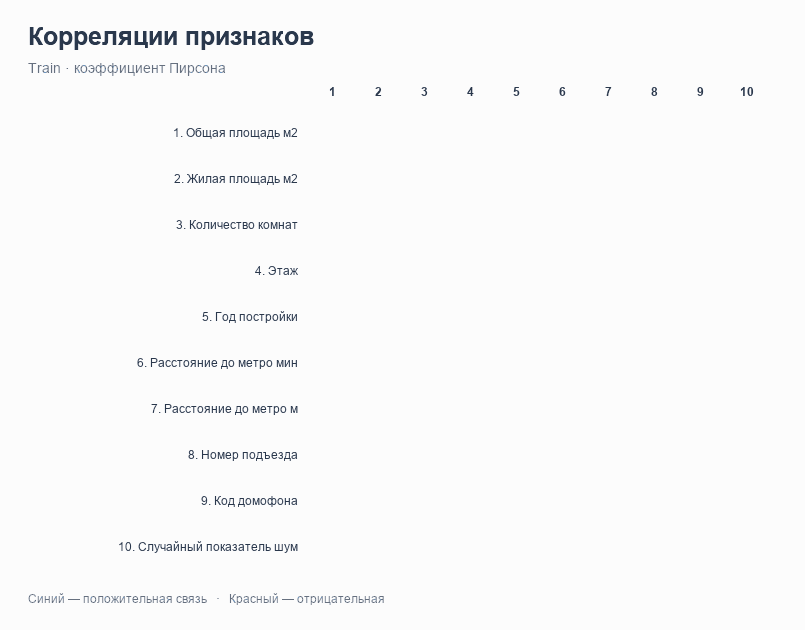

In [18]:
# 1. Сначала плавно появляется вся нейтральная таблица, затем — её цвета.
labels = [s.replace("_", " ") for s in corr_matrix.columns]
count = len(labels)
left, top, size = 310, 110, 46
base, draw = new_frame(left+count*size+35, top+count*size+60,
                       "Корреляции признаков", "Train · коэффициент Пирсона")
for i, label in enumerate(labels):
    draw.text((left-12, top+i*size+size//2), f"{i+1}. {label}", fill="#334155", font=chart_font(12), anchor="rm")
    draw.text((left+i*size+size//2, top-18), str(i+1), fill="#334155", font=chart_font(12, True), anchor="mm")
draw.text((28, top+count*size+22), "Синий — положительная связь   ·   Красный — отрицательная", fill="#718096", font=chart_font(12))
neutral, final = base.copy(), base.copy()
neutral_draw, final_draw = ImageDraw.Draw(neutral), ImageDraw.Draw(final)
for i in range(count):
    for j in range(count):
        value = corr_matrix.iloc[i, j]
        strength = abs(value)
        color = (int(245-180*strength), int(248-105*strength), int(252-30*strength)) if value >= 0 else (int(252-25*strength), int(246-145*strength), int(245-130*strength))
        x, y = left+j*size, top+i*size
        for target, fill, text_color in [(neutral_draw, "#f0f3f7", "#526174"),
                                         (final_draw, color, "white" if strength > .65 else "#263449")]:
            target.rounded_rectangle((x, y, x+size-3, y+size-3), radius=6, fill=fill)
            target.text((x+size//2, y+size//2), f"{value:.2f}", fill=text_color, font=chart_font(12), anchor="mm")
frames = [PILImage.blend(base, neutral, smooth(t)) for t in np.linspace(0, 1, 30)]
frames += [neutral.copy() for _ in range(8)]
frames += [PILImage.blend(neutral, final, smooth(t)) for t in np.linspace(0, 1, 75)]
show_gif(frames, "01_correlations.gif")

### Сравнение методов

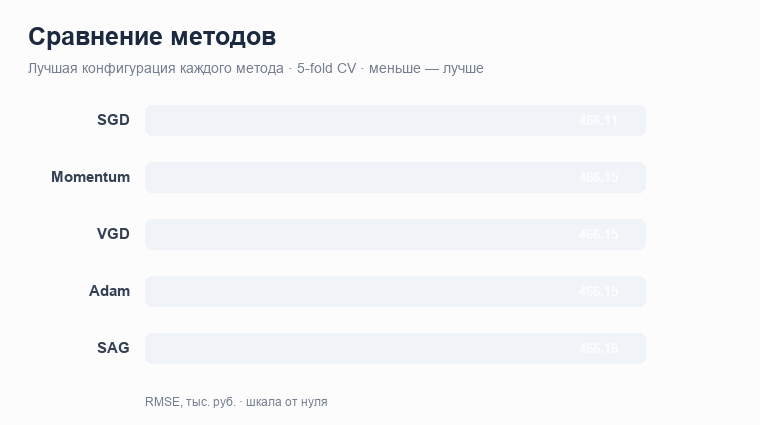

In [19]:
# 2. Плавное ускорение и замедление роста столбцов; значения появляются мягко.
best_by_method = results_df.loc[results_df.groupby("Метод")["RMSE_CV"].idxmin()].sort_values("RMSE_CV")
max_error = best_by_method["RMSE_CV"].max()*1.18
frames = []
for step in range(100):
    progress = step/99
    image, draw = new_frame(760, 425, "Сравнение методов", "Лучшая конфигурация каждого метода · 5-fold CV · меньше — лучше")
    left, top, width = 145, 105, 500
    for i, (_, row) in enumerate(best_by_method.iterrows()):
        y = top+i*57
        grow = smooth((progress-i*0.025)/0.86)
        bar_width = width*row["RMSE_CV"]/max_error*grow
        draw.text((left-15, y+15), row["Метод"], fill="#334155", font=chart_font(15, True), anchor="rm")
        draw.rounded_rectangle((left, y, left+width, y+30), radius=6, fill="#f3f6fa")
        if bar_width >= 1:
            draw.rounded_rectangle((left, y, left+bar_width, y+30), radius=min(6, bar_width/2), fill="#2563eb" if i == 0 else "#a8c6ef")
        fade = smooth((progress-.72)/.28)
        draw.text((left+width*row["RMSE_CV"]/max_error+10, y+15), f'{row["RMSE_CV"]:.2f}',
                  fill=mix_color("#ffffff", "#263449", fade), font=chart_font(13, True), anchor="lm")
    draw.text((left, 395), "RMSE, тыс. руб. · шкала от нуля", fill="#718096", font=chart_font(12))
    frames.append(image)
show_gif(frames, "02_methods.gif")

### Фактическая и предсказанная стоимость

In [20]:
# 3. Точки мягко проявляются; положение соответствует фактическому прогнозу.
actual = np.asarray(y_true_test, dtype=float)
predicted = np.asarray(y_pred_test, dtype=float)
lo, hi = min(actual.min(), predicted.min()), max(actual.max(), predicted.max())
pad = (hi-lo)*.04
lo, hi = lo-pad, hi+pad
left, top, side = 110, 115, 400
def coord_x(v): return left+(v-lo)/(hi-lo)*side
def coord_y(v): return top+side-(v-lo)/(hi-lo)*side
base, draw = new_frame(760, 590, "Прогноз на тестовой выборке", f"R² = {r2_test:.4f}  ·  RMSE = {rmse_test:.1f} тыс. руб.")
for tick in np.linspace(lo, hi, 5):
    x, y = coord_x(tick), coord_y(tick)
    draw.line((x, top, x, top+side), fill="#e8edf4")
    draw.line((left, y, left+side, y), fill="#e8edf4")
    label = f"{tick:,.0f}".replace(",", " ")
    draw.text((x, top+side+10), label, fill="#718096", font=chart_font(11), anchor="mt")
    draw.text((left-10, y), label, fill="#718096", font=chart_font(11), anchor="rm")
draw.line((left, top+side, left+side, top), fill="#ef8d63", width=2)
draw.text((left, top-25), "Прогноз, тыс. руб.", fill="#334155", font=chart_font(13))
draw.text((left+side/2, top+side+42), "Фактическая стоимость, тыс. руб.", fill="#334155", font=chart_font(13), anchor="mt")
draw.text((left+side+20, top+10), "Идеальный прогноз", fill="#c76c48", font=chart_font(12))
# Проявление движется слева направо, каждая точка плавно набирает непрозрачность.
rank = np.empty(len(actual), dtype=float)
rank[np.argsort(actual)] = np.linspace(0, .68, len(actual))
frames = []
for step in range(110):
    image = base.copy()
    layer = PILImage.new("RGBA", image.size)
    points = ImageDraw.Draw(layer)
    progress = step/109
    for index, (a, p) in enumerate(zip(actual, predicted)):
        opacity = smooth((progress-rank[index])/.32)
        if opacity <= 0:
            continue
        x, y = coord_x(a), coord_y(p)
        radius = 3.4
        points.ellipse((x-radius, y-radius, x+radius, y+radius), fill=(37, 99, 190, round(210*opacity)))
    image.paste(layer, (0, 0), layer)
    frames.append(image)
show_gif(frames, "03_predictions.gif", full_frames=True)

TypeError: show_gif() got an unexpected keyword argument 'full_frames'